In [2]:
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langchain.messages import RemoveMessage

In [3]:
load_dotenv()

True

In [4]:
model = ChatOpenAI(model_name="gpt-4o-mini")

In [5]:
def chat(state: MessagesState):
    response = model.invoke(state["messages"])
    return {"messages": [response]}

In [6]:
def delete_old_messages(state: MessagesState):
    msgs = state["messages"]

    # if more than 10 messages, delete the earliest 6
    if len(msgs) > 10:
        to_remove = msgs[:6]
        return {"messages": [RemoveMessage(id=m.id) for m in to_remove]}

    return {}

In [7]:
builder = StateGraph(MessagesState)
builder.add_node("chat", chat)
builder.add_node("cleanup", delete_old_messages)

In [11]:
builder.add_edge(START, "chat")
builder.add_edge("chat", "cleanup")

Adding an edge to a graph that has already been compiled. This will not be reflected in the compiled graph.
Adding an edge to a graph that has already been compiled. This will not be reflected in the compiled graph.


In [12]:
checkpointer=InMemorySaver()

graph = builder.compile(checkpointer=checkpointer)

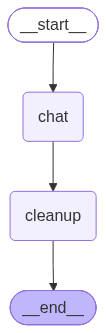

In [13]:
graph

In [14]:
config = {"configurable": {"thread_id": "t1"}}

In [15]:
# Run multiple turns
graph.invoke({"messages": [{"role": "user", "content": "Hi, I'm Hussain"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "Tell me about LangGraph"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "Now explain checkpointers"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Langchain"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Quantum Mechanics"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Gen AI"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is my name"}]}, config)

{'messages': [HumanMessage(content='What is Langchain', additional_kwargs={}, response_metadata={}, id='98b0cb3c-418c-46a2-9a51-bb397036f419'),
  AIMessage(content="LangChain is a framework designed to facilitate the development of applications that utilize language models, particularly those based on artificial intelligence and natural language processing (NLP). It provides tools and components to help developers integrate large language models (LLMs) into their applications more effectively. Here are some key aspects and features of LangChain:\n\n1. **Components**: LangChain offers various components such as:\n   - **Prompt Management**: Tools to create, modify, and manage prompts that are sent to language models.\n   - **Chains**: These are sequences of operations or tasks that can be executed in order, allowing for more complex workflows.\n   - **Agents**: These represent intelligent agents that can decide what actions to take based on user input, consisting of a chain of actions.\

In [16]:
snap = graph.get_state(config)
print("Stored messages after cleanup:", len(snap.values["messages"]))

Stored messages after cleanup: 8
